<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 54 — PCA'ya giriş: gölgeden hikâye">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-54-0B3A52?style=for-the-badge" alt="Gün 54">
  <img src="https://img.shields.io/badge/Konu-PCA_(Kavram)-E5A100?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-Kuru_Fasulye_(Kaggle)-0EA5C6?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Animasyon-5_GIF-D1495B?style=for-the-badge" alt="Animasyon">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🔦</h3><b>Işık ve gölge</b><br><br>Veriye <b>doğru açıdan</b> bak,<br>gölgesi en çok bilgiyi taşısın<br><br></td><td width="25%" valign="top" align="center"><h3>📏</h3><b>En geniş yayılım</b><br><br>İlk eksen verinin<br><b>en çok yayıldığı</b> yöndür<br><br></td><td width="25%" valign="top" align="center"><h3>🧭</h3><b>Dik yeni eksenler</b><br><br>Her eksen öncekine <b>dik</b>,<br>birbirinden bağımsız<br><br></td><td width="25%" valign="top" align="center"><h3>🫘</h3><b>13.543 fasulye</b><br><br>16 ölçü, <b>2 eksenli bir haritaya</b><br>sığıyor mu? Deneyelim<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 😵 **Boyut laneti** nedir, gürültü ölçüler modeli nasıl bozar? Deneyle görmek
- 🔦 PCA'yı **"gölge"** benzetmesiyle, matematiğe boğulmadan anlatmak
- 🧮 8 fasulyeyle **elle PCA** yapmak (kovaryans → özvektör → izdüşüm) ve `scikit-learn` ile doğrulamak
- ➗ Neden **standartlaştırma** şart olduğunu ölçmek
- 📉 **Kaç bileşen yeter?** sorusuna 5 farklı kuralla cevap vermek
- 🗺️ 16 ölçüyü **2 eksenli haritaya** indirip fasulye türlerini görmek
- 🔄 Sıkıştırılan bilgiyi **geri kurmak** ve ne kaybolduğunu görmek
- ⚠️ PCA'nın **tuzaklarını** (sızıntı, gizli ayrım, aykırı değer) tanımak

Teknik ayrıntı bilinçli olarak az tutuldu; her kavramın yanında **bir resim, bir animasyon ve bir deney** var.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yol haritası: 11 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#p1) | Hangi araçlarla çalışıyoruz? |
| 😵 2 | [Boyut laneti](#p2) | Ölçü sayısı artınca neden işler kötüleşir? |
| 🔦 3 | [Gölge fikri](#p3) | PCA'nın tek cümlelik fikri nedir? |
| 🧮 4 | [8 fasulye, elle PCA](#p4) | Adım adım nasıl hesaplanır? |
| ➗ 5 | [Standartlaştırma](#p5) | Ölçekler farklıysa ne olur? |
| 📉 6 | [Kaç bileşen?](#p6) | Kaç eksen tutmalıyız? |
| 🗺️ 7 | [Fasulye haritası](#p7) | 16 ölçü 2 eksene sığar mı? |
| 🔄 8 | [Geri kurma](#p8) | Sıkıştırınca ne kaybolur? |
| ⚠️ 9 | [Tuzaklar](#p9) | PCA nerede yanıltır? |
| 🎞️ 10 | [Canlı PCA](#p10) | Tüm adımlar tek filmde |
| 🎓 11 | [Özet](#p11) | Akılda kalanlar, quiz, ödevler, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1">
</p>

Kütüphaneleri ve çizim yardımcılarını tek hücrede topluyoruz. Animasyonlar `outputs/figures` klasörüne **GIF** olarak kaydedilir ve notebook içinde oynatılır.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from fasulye_yardimci import veri_oku, OZELLIKLER, HEDEF, TR_AD, SINIF_TR

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (gece mavisi + fasulye altını)
RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "cyan": "#0E9AA7", "yesil": "#2E9E6B", "pembe": "#D1495B",
        "mor": "#6C5CE7", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#1F2A44"}
SINIF_RENK = dict(zip(sorted(SINIF_TR.values()),
                      ["#E5A100", "#2B6CB0", "#D1495B", "#2E9E6B", "#6C5CE7", "#E8833A", "#0E9AA7"]))
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8, 4.4), fps=6):
    """kare_ciz(i, fig) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


<a id="p2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2">
</p>

### 🫘 2.1 · Bu Derste Kullanacağımız Veri: Kuru Fasulye

Bir fabrikada **7 çeşit kuru fasulye** kameradan geçiyor. Her fasulyenin fotoğrafından **16 şekil ölçüsü** (alan, çevre, uzun/kısa eksen, yuvarlaklık…) çıkarılmış. Veri, **Kaggle'daki "Dry Bean Dataset"** (Koklu ve Özkan, 2020): **13.611 fasulye**. Amaç: ölçülerden **türü** bulmak.

> 🔎 Bu çalışma ortamında Kaggle'a doğrudan erişim kapalıydı; aynı dosya bir GitHub aynasından indirildi ve Kaggle sayfasındaki satır/sütun/sınıf sayılarıyla **birebir** doğrulandı (13.611 × 17, 7 sınıf). Dosya depoda `25-dry-bean.csv` adıyla durur.

In [2]:
ham = veri_oku()
print("Satır, sütun:", ham.shape)
display(ham.head(4))
print("\nTür dağılımı:"); print(ham[HEDEF].value_counts().to_string())
print("\nTamamen aynı satır (kopya) sayısı:", ham.duplicated().sum())

# Kopya satırları çıkarıyoruz (aynı fasulye hem eğitimde hem testte olmasın diye; projede ayrıca ölçeceğiz)
d = ham.drop_duplicates().reset_index(drop=True)
X = d[OZELLIKLER].rename(columns=TR_AD)         # Türkçe sütun adları
y = d[HEDEF].map(SINIF_TR)
print("\nKopyasız veri:", X.shape)

Satır, sütun: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER



Tür dağılımı:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522

Tamamen aynı satır (kopya) sayısı: 68

Kopyasız veri: (13543, 16)


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Boyut = sütun sayısı.** Elimizde 16 sütun var, yani her fasulye 16 boyutlu uzayda **bir nokta**. İnsan gözü 3 boyuttan ötesini göremez; PCA bu uzayı **gölgesine** indirip bakmamızı sağlar.

</td></tr></table>

### 😵 2.2 · Boyut Laneti (Curse of Dimensionality)

Ders notundaki örneği gerçek veriyle deneyelim: *10 anlamlı değişkenin yanına 90 gereksiz değişken eklersek model doğru sinyali gürültüden ayıramaz.*

Fasulye ölçülerinin yanına **yapay gürültü sütunları** ekleyeceğiz (rastgele sayılar, türle hiçbir ilgisi yok) ve üç modelin doğruluğunu izleyeceğiz: **kNN** (komşuya bakar, gürültüden çok etkilenir), **lojistik regresyon** ve **PCA + kNN**.

<p align="center">
  <img src="assets/diyagram_boyut_laneti.svg" width="100%" alt="Boyut laneti">
</p>

,Toplam sütun,kNN,Lojistik regresyon,PCA(4) + kNN
Gürültü sütunu,,,,
0,16,0.918,0.921,0.875
10,26,0.860,0.918,0.854
30,46,0.782,0.912,0.847
90,106,0.662,0.884,0.847
200,216,0.572,0.840,0.836
500,516,0.455,0.765,0.819


💾 Kaydedildi → outputs/figures/kavram_01_boyut_laneti.png


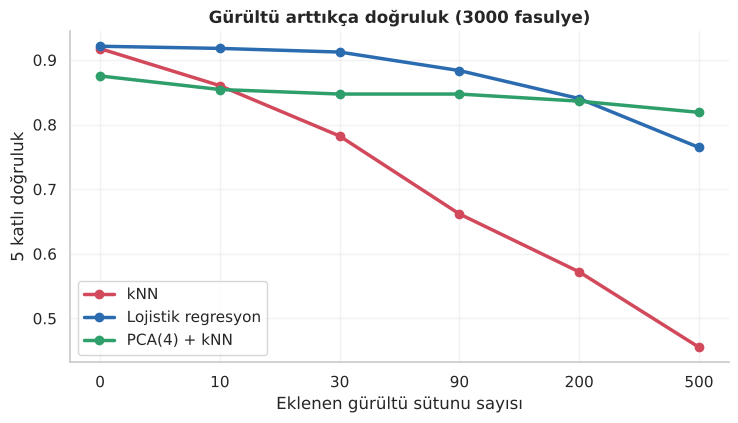

📄 Rapor → outputs/reports/kavram_boyut_laneti.csv


In [3]:
rng = np.random.default_rng(RANDOM_STATE)
ornek = d.sample(3000, random_state=RANDOM_STATE)             # hız için 3000 fasulye
Xo = ornek[OZELLIKLER].to_numpy(); yo = ornek[HEDEF].to_numpy()
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

sonuc = []
for n_gurultu in [0, 10, 30, 90, 200, 500]:
    Xg = np.hstack([Xo, rng.normal(size=(len(Xo), n_gurultu))])     # yapay gürültü sütunları
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    pknn = make_pipeline(StandardScaler(), PCA(n_components=4), KNeighborsClassifier())
    sonuc.append({"Gürültü sütunu": n_gurultu, "Toplam sütun": Xg.shape[1],
                  "kNN": cross_val_score(knn, Xg, yo, cv=cv5).mean(),
                  "Lojistik regresyon": cross_val_score(lr, Xg, yo, cv=cv5).mean(),
                  "PCA(4) + kNN": cross_val_score(pknn, Xg, yo, cv=cv5).mean()})
gl = pd.DataFrame(sonuc).set_index("Gürültü sütunu")
display(gl.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
for s, r in [("kNN", RENK["pembe"]), ("Lojistik regresyon", RENK["mavi"]), ("PCA(4) + kNN", RENK["yesil"])]:
    ax.plot(gl.index.astype(str), gl[s], "o-", lw=2.5, color=r, label=s)
ax.set_xlabel("Eklenen gürültü sütunu sayısı"); ax.set_ylabel("5 katlı doğruluk")
ax.set_title("Gürültü arttıkça doğruluk (3000 fasulye)"); ax.legend()
kaydet(fig, "kavram_01_boyut_laneti"); plt.show()
rapor_kaydet(gl, "kavram_boyut_laneti")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Tablo ders notundaki uyarıyı doğruluyor: **gürültü sütunları eklendikçe kNN çöker** (0,92 → 0,46). Lojistik regresyon daha dayanıklı ama o da düşer (0,92 → 0,77). **PCA(4) + kNN** ise en yavaş düşendir: gürültü yokken biraz geride (4 bileşen bilgiyi tam taşımıyor), ama **30+ gürültü sütununda kNN'yi, 500 sütunda lojistik regresyonu da geçer**. Neden? Gürültü sütunları birbirinden bağımsız olduğu için PCA'nın ilk eksenlerini **gerçek (birlikte değişen) fasulye ölçüleri** kazanır.

</td></tr></table>

Boyut lanetinin ikinci yüzü **mesafelerdir**: Boyut artınca *en yakın komşu ile en uzak komşu* birbirine benzemeye başlar; "yakın" kavramı anlamını yitirir. Rastgele noktalarla ölçelim:

,(en uzak − en yakın) / en yakın
Boyut,
2,113.116
5,7.743
10,2.279
50,0.650
100,0.442
500,0.160
1000,0.119
3000,0.072


💾 Kaydedildi → outputs/figures/kavram_02_mesafe_cokusu.png


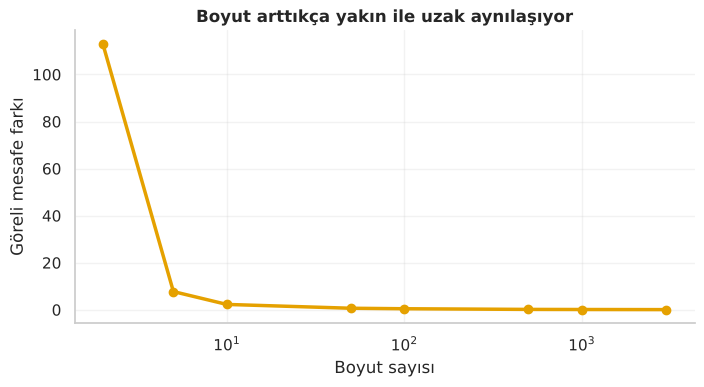

In [4]:
rng = np.random.default_rng(1)
satirlar = []
for boyut in [2, 5, 10, 50, 100, 500, 1000, 3000]:
    P = rng.random((1000, boyut)); q = rng.random(boyut)
    mesafe = np.linalg.norm(P - q, axis=1)
    satirlar.append({"Boyut": boyut, "(en uzak − en yakın) / en yakın": (mesafe.max() - mesafe.min()) / mesafe.min()})
mt = pd.DataFrame(satirlar).set_index("Boyut")
display(mt.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogx(mt.index, mt.iloc[:, 0], "o-", lw=2.5, color=RENK["altin"])
ax.set_xlabel("Boyut sayısı"); ax.set_ylabel("Göreli mesafe farkı"); ax.set_title("Boyut arttıkça yakın ile uzak aynılaşıyor")
kaydet(fig, "kavram_02_mesafe_cokusu"); plt.show()

### ✂️ 2.3 · Çare: Seçmek mi, Çıkarmak mı?

<p align="center">
  <img src="assets/diyagram_secim_cikarim.svg" width="100%" alt="Özellik seçimi ve özellik çıkarımı">
</p>

- **Özellik seçimi:** var olan ölçülerden **bazılarını tutar**, gerisini atar.
- **Özellik çıkarımı (PCA):** ölçüleri **birleştirerek yeni ölçüler** üretir; hiçbir ölçüyü tamamen çöpe atmaz ama **az bilgi taşıyan yönleri** eler.

<a id="p3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3">
</p>

### 🔦 3.1 · Gölge Benzetmesi

Elinizde 3 boyutlu bir cisim olsun (mesela bir fasulye tanesi) ve duvara **gölgesini** düşürün. Işığı hangi açıdan tutarsanız tutun gölge 2 boyutludur ama **bazı açılar cismi çok iyi anlatır, bazıları kötü**: fasulyeyi tam karşıdan tutarsanız gölge bir **yuvarlak**, yandan tutarsanız **uzun bir oval** olur; oval, cisim hakkında çok daha fazla bilgi verir.

**PCA, ışığı "gölge en geniş yayılsın" diye döndürüp en iyi açıyı bulan yöntemdir.**

<p align="center">
  <img src="assets/diyagram_pca_fikri.svg" width="100%" alt="PCA'nın fikri">
</p>

Şimdi bunu iki gerçek ölçüyle (**uzun eksen** ve **kısa eksen**) canlı izleyelim. Bir doğru (ışığın duvarı) 0°'den 180°'ye dönüyor; noktaların bu doğruya düşen gölgelerinin **yayılımını** (varyansını) sağdaki eğri gösteriyor.

Gölge yayılımı en büyük açı ≈ 45°  (PCA'nın 1. ekseni)


🎞️ Animasyon → outputs/figures/kavram_03_golge_animasyonu.gif


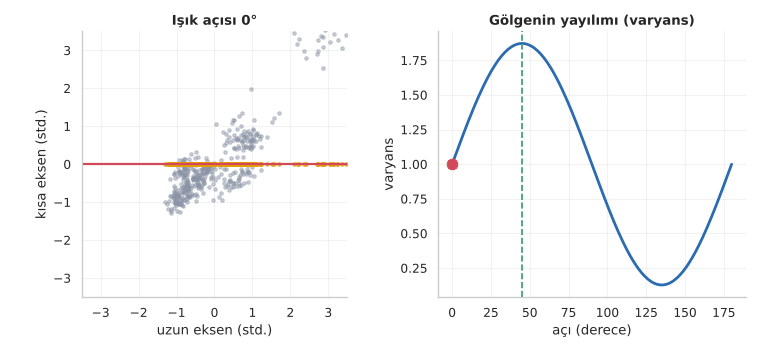

In [5]:
ik = X[["Uzun eksen", "Kısa eksen"]].sample(400, random_state=RANDOM_STATE)
Zik = StandardScaler().fit_transform(ik)                   # ortalama 0, yayılım 1
acilar = np.arange(0, 181, 6)
def yayilim(a):                                            # a derece doğruya düşen gölgelerin varyansı
    v = np.array([np.cos(np.radians(a)), np.sin(np.radians(a))]); return (Zik @ v).var()
yay = np.array([yayilim(a) for a in np.arange(0, 181, 1)])
en_iyi = np.arange(0, 181, 1)[yay.argmax()]
print(f"Gölge yayılımı en büyük açı ≈ {en_iyi}°  (PCA'nın 1. ekseni)")

def kare(i, fig):
    a = acilar[i]; th = np.radians(a); v = np.array([np.cos(th), np.sin(th)])
    ax1 = fig.add_subplot(1, 2, 1); ax2 = fig.add_subplot(1, 2, 2)
    ax1.scatter(Zik[:, 0], Zik[:, 1], s=10, color=RENK["gri"], alpha=.45)
    gol = np.outer(Zik @ v, v)
    ax1.scatter(gol[:, 0], gol[:, 1], s=9, color=RENK["altin"], alpha=.8)
    ax1.plot([-4 * v[0], 4 * v[0]], [-4 * v[1], 4 * v[1]], color=RENK["pembe"], lw=2)
    ax1.set_xlim(-3.5, 3.5); ax1.set_ylim(-3.5, 3.5); ax1.set_aspect("equal")
    ax1.set_title(f"Işık açısı {a}°"); ax1.set_xlabel("uzun eksen (std.)"); ax1.set_ylabel("kısa eksen (std.)")
    ax2.plot(np.arange(0, 181), yay, color=RENK["mavi"], lw=2.5)
    ax2.scatter([a], [yayilim(a)], s=90, color=RENK["pembe"], zorder=5)
    ax2.axvline(en_iyi, color=RENK["yesil"], ls="--"); ax2.set_title("Gölgenin yayılımı (varyans)")
    ax2.set_xlabel("açı (derece)"); ax2.set_ylabel("varyans")
    fig.tight_layout()
gif_kaydet(kare, len(acilar), "kavram_03_golge_animasyonu", figsize=(9.5, 4.4), fps=6)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Gölge en geniş olduğunda (yeşil kesikli çizgi) altın noktalar **birbirinden en uzak** durur; yani veri **en az sıkışmış, en çok bilgi taşıyan** hâldedir. Bu doğru PCA'nın **1. bileşenidir (PC1)**. Ona **dik** doğru ise 2. bileşendir (PC2).

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4">
</p>

### 🧮 4.1 · PCA'nın Beş Adımı

<p align="center">
  <img src="assets/diyagram_bes_adim.svg" width="100%" alt="PCA'nın beş adımı">
</p>

8 fasulye ve 2 ölçü (uzun eksen, kısa eksen) alalım ki her şeyi **elle** görebilelim.

In [6]:
idx8 = d.sample(8, random_state=3).index                    # 8 rastgele fasulye
sekiz = d.loc[idx8, OZELLIKLER].rename(columns=TR_AD); sekiz.index = list("ABCDEFGH")
M = sekiz[["Uzun eksen", "Kısa eksen"]].astype(float)
tablo = M.copy(); tablo["Tür"] = d.loc[idx8, HEDEF].map(SINIF_TR).values
display(tablo.round(1))

,Uzun eksen,Kısa eksen,Tür
A,326.4,206.7,Sıra
B,247.4,172.6,Dermason
C,235.3,170.3,Dermason
D,342.5,215.4,Barbunya
E,636.1,402.3,Bombay
F,424.3,236.1,Çalı
G,232.3,191.5,Şeker
H,256.1,194.8,Şeker


**Adım 1 · Standartlaştır:** her sütundan ortalamayı çıkarıp standart sapmaya böleriz (ders notundaki $X_{scaled} = (X-\mu)/\sigma$).

In [7]:
ort, std = M.mean(), M.std(ddof=1)
Z = (M - ort) / std
display(pd.concat([ort.rename("ortalama"), std.rename("std. sapma")], axis=1).T.round(2))
display(Z.round(2))

,Uzun eksen,Kısa eksen
ortalama,337.55,223.72
std. sapma,137.89,75.36


,Uzun eksen,Kısa eksen
A,-0.08,-0.23
B,-0.65,-0.68
C,-0.74,-0.71
D,0.04,-0.11
E,2.17,2.37
F,0.63,0.16
G,-0.76,-0.43
H,-0.59,-0.38


**Adım 2 · Kovaryans matrisi:** iki ölçü *birlikte* nasıl değişiyor? (Standartlaştırdığımız için bu matris aynı zamanda **korelasyon** matrisidir.)

In [8]:
C = np.cov(Z.to_numpy().T)          # 2x2 kovaryans matrisi
print("Kovaryans matrisi:\n", C.round(3))
print("\nKöşegen = her ölçünün kendi yayılımı (1), köşegen dışı = ikisinin birlikte değişimi.")

Kovaryans matrisi:
 [[1.    0.967]
 [0.967 1.   ]]

Köşegen = her ölçünün kendi yayılımı (1), köşegen dışı = ikisinin birlikte değişimi.


**Adım 3 · Özvektör ve özdeğer:** $A\vec v = \lambda \vec v$. Özvektör = veri **hangi yöne** yayılıyor, özdeğer = o yönde **ne kadar** yayılıyor.

<p align="center">
  <img src="assets/diyagram_ozvektor.svg" width="100%" alt="Özvektör ve özdeğer">
</p>

In [9]:
lam, V = np.linalg.eigh(C)                 # simetrik matris için özdeğer ayrıştırması
sira = lam.argsort()[::-1]                 # Adım 4: büyükten küçüğe sırala
lam, V = lam[sira], V[:, sira]
print("Özdeğerler (λ):", lam.round(3), "→ toplam =", lam.sum().round(3))
print("Açıklanan varyans oranı:", (lam / lam.sum()).round(3))
print("\nÖzvektörler (sütun = bileşen):\n", pd.DataFrame(V, index=["Uzun eksen", "Kısa eksen"], columns=["PC1", "PC2"]).round(3))

Özdeğerler (λ): [1.967 0.033] → toplam = 2.0
Açıklanan varyans oranı: [0.984 0.016]

Özvektörler (sütun = bileşen):
               PC1    PC2
Uzun eksen  0.707 -0.707
Kısa eksen  0.707  0.707


**Adım 5 · Projeksiyon:** $Z_{yeni} = Z \cdot W$. Her fasulyeyi yeni eksenlere izdüşürürüz.

Elle ↔ scikit-learn en büyük fark: 4.44e-16  (≈ 0 → birebir aynı)


,PC1,PC2
A,-0.22,-0.10
B,-0.94,-0.02
C,-1.03,0.02
D,-0.05,-0.10
E,3.21,0.14
F,0.56,-0.33
G,-0.84,0.24
H,-0.69,0.15


💾 Kaydedildi → outputs/figures/kavram_04_elle_pca.png


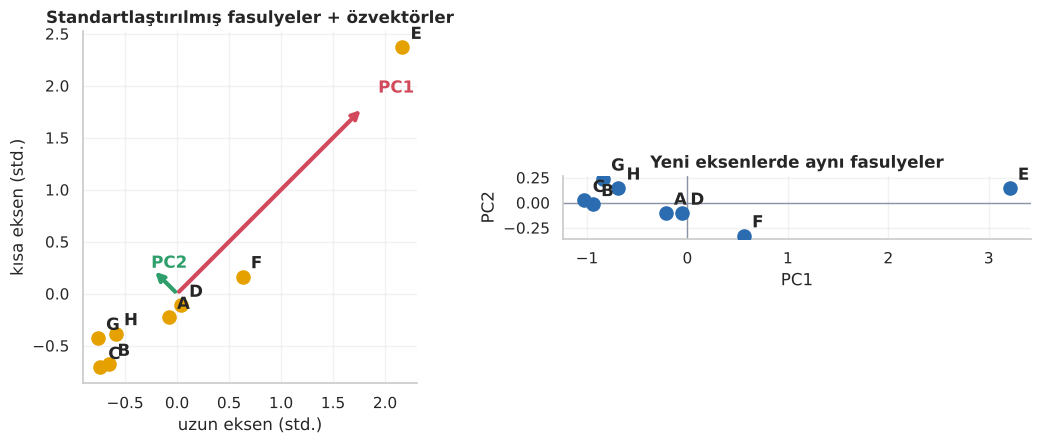

In [10]:
skor = Z.to_numpy() @ V                    # elle bulunan yeni koordinatlar
sk = PCA(n_components=2).fit_transform(Z)  # aynı işi scikit-learn ile yap
fark = np.abs(np.abs(skor) - np.abs(sk)).max()      # eksen işareti keyfi (±), bu yüzden mutlak değer
print(f"Elle ↔ scikit-learn en büyük fark: {fark:.2e}  (≈ 0 → birebir aynı)")
display(pd.DataFrame(skor, index=Z.index, columns=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].scatter(Z.iloc[:, 0], Z.iloc[:, 1], s=90, color=RENK["altin"], zorder=3)
for ad, (a, b) in zip(Z.index, Z.to_numpy()): ax[0].annotate(ad, (a, b), xytext=(6, 6), textcoords="offset points", fontweight="bold")
for j, r in enumerate([RENK["pembe"], RENK["yesil"]]):
    ax[0].annotate("", xy=V[:, j] * np.sqrt(lam[j]) * 1.8, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=r, lw=3))
    ax[0].text(*(V[:, j] * np.sqrt(lam[j]) * 1.95), f"PC{j+1}", color=r, fontweight="bold")
ax[0].set_aspect("equal"); ax[0].set_title("Standartlaştırılmış fasulyeler + özvektörler")
ax[0].set_xlabel("uzun eksen (std.)"); ax[0].set_ylabel("kısa eksen (std.)")
ax[1].scatter(skor[:, 0], skor[:, 1], s=90, color=RENK["mavi"], zorder=3)
for ad, (a, b) in zip(Z.index, skor): ax[1].annotate(ad, (a, b), xytext=(6, 6), textcoords="offset points", fontweight="bold")
ax[1].axhline(0, color=RENK["gri"], lw=1); ax[1].axvline(0, color=RENK["gri"], lw=1)
ax[1].set_aspect("equal"); ax[1].set_title("Yeni eksenlerde aynı fasulyeler"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
fig.tight_layout(); kaydet(fig, "kavram_04_elle_pca"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Elle yaptığımız hesap ile `scikit-learn`'ün sonucu **aynı** (fark ≈ 10⁻¹⁶). PCA büyülü bir kara kutu değil: **kovaryans matrisinin özvektörlerine dönmek** ve verinin **en çok yayıldığı yönden** bakmaktır. PC1 neredeyse tüm yayılımı taşıyor; çünkü uzun eksen ve kısa eksen **birlikte büyüyüp küçülüyor** (büyük fasulye her iki yönde de büyük).

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5">
</p>

### ➗ 5.1 · Büyük Sayılar Haksız Üstünlük Kurar

Alan (örneğin 50.000 piksel) ile eksantriklik (0,7) aynı birimde değil. **Standartlaştırmazsak** PCA "en çok yayılan" ölçüyü bulmaya çalışırken **sırf sayıları büyük olan** ölçüleri seçer. Denemek için iki PCA kuralım: ölçeksiz ve ölçekli.

Ölçeksiz PCA → PC1 tek başına varyansın %99.997'ini 'taşıyor'
Ölçekli  PCA → PC1 varyansın %55.5'ini taşıyor


,Ölçeksiz PC1 yükü,Ölçekli PC1 yükü
Alan,0.702,0.283
Çevre,0.005,0.311
Uzun eksen,0.002,0.326
Kısa eksen,0.001,0.237
En-boy oranı,0.000,0.229
Basıklık (eksantriklik),0.000,0.231
Dışbükey alan,0.712,0.283
Eş çap,0.001,0.297
Kaplama oranı,0.000,-0.060
Doluluk,-0.000,-0.143


,Ölçeksiz PCA + kNN,Ölçekli PCA + kNN
Bileşen sayısı,,
1,0.582,0.572
2,0.648,0.855
3,0.700,0.871
4,0.723,0.882
6,0.724,0.921
8,0.724,0.923


💾 Kaydedildi → outputs/figures/kavram_05_olcekleme.png


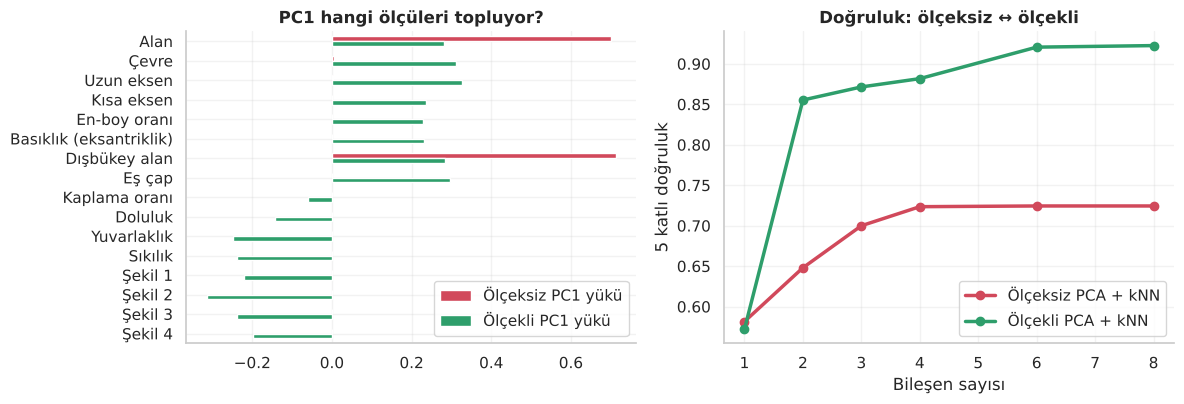

📄 Rapor → outputs/reports/kavram_olcekleme.csv


In [11]:
Xh = d[OZELLIKLER].rename(columns=TR_AD)
p_ham = PCA().fit(Xh)                                   # ölçeklemeden
p_std = PCA().fit(StandardScaler().fit_transform(Xh))   # ölçekleyerek
print(f"Ölçeksiz PCA → PC1 tek başına varyansın %{p_ham.explained_variance_ratio_[0]*100:.3f}'ini 'taşıyor'")
print(f"Ölçekli  PCA → PC1 varyansın %{p_std.explained_variance_ratio_[0]*100:.1f}'ini taşıyor")

yuk = pd.DataFrame({"Ölçeksiz PC1 yükü": p_ham.components_[0], "Ölçekli PC1 yükü": p_std.components_[0]}, index=Xh.columns)
display(yuk.round(3))

# Sınıflandırma başarısı: kaç bileşen tutarsak tutalım, ölçeksiz PCA daha mı kötü?
yh = d[HEDEF]
sat = []
for k in [1, 2, 3, 4, 6, 8]:
    sat.append({"Bileşen sayısı": k,
                "Ölçeksiz PCA + kNN": cross_val_score(make_pipeline(PCA(k), KNeighborsClassifier()), Xh, yh, cv=cv5).mean(),
                "Ölçekli PCA + kNN": cross_val_score(make_pipeline(StandardScaler(), PCA(k), KNeighborsClassifier()), Xh, yh, cv=cv5).mean()})
ol = pd.DataFrame(sat).set_index("Bileşen sayısı")
display(ol.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
yuk.plot.barh(ax=ax[0], color=[RENK["pembe"], RENK["yesil"]]); ax[0].set_title("PC1 hangi ölçüleri topluyor?"); ax[0].invert_yaxis()
ol.plot(ax=ax[1], marker="o", lw=2.5, color=[RENK["pembe"], RENK["yesil"]]); ax[1].set_title("Doğruluk: ölçeksiz ↔ ölçekli"); ax[1].set_ylabel("5 katlı doğruluk")
fig.tight_layout(); kaydet(fig, "kavram_05_olcekleme"); plt.show()
rapor_kaydet(ol, "kavram_olcekleme")

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Ölçeksiz PCA'da PC1 neredeyse **yalnızca alan ve dışbükey alan** gibi büyük sayılı ölçülerden oluşur; çünkü onların varyansı milyonlarla ölçülür. Bu yüzden PCA'dan önce **`StandardScaler` neredeyse her zaman şarttır** (ölçülerin hepsi zaten aynı birimdeyse istisna).

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6">
</p>

### 📉 6.1 · Kaç Bileşen Tutalım?

Bütün 16 ölçüye PCA uygulayınca 16 bileşen çıkar; **ilkleri çok, sonrakiler çok az** bilgi taşır. Peki nerede keselim? Beş farklı kural var:

1. **Kaiser kuralı:** özdeğeri 1'den büyük olanları tut (tek bir orijinal ölçüden daha fazla bilgi taşıyanlar)
2. **%95 kuralı:** toplam varyansın %95'ine ulaşana kadar tut
3. **Dirsek (scree):** eğri keskin bükülünce dur
4. **Paralel analiz:** karıştırılmış (rastgele) veriden çıkan özdeğerleri aşanları tut
5. **Doğrulama:** bileşen sayısını **model başarısıyla** seç (en güvenilir yol)

> 🔎 Bu bölüm **keşif amaçlıdır**: PCA'yı tüm veriye uyguluyoruz. Projede (ayrı notebook) PCA yalnızca eğitim katlarında öğrenilecek.

,Önerdiği bileşen sayısı
Kural,
Kaiser (λ>1),3
%95 varyans,4
Dirsek,3
Paralel analiz,3
Minka MLE,15


,kNN,Lojistik
k,,
1,0.572,0.628
2,0.855,0.870
3,0.871,0.878
4,0.882,0.889
5,0.919,0.922
6,0.921,0.923
7,0.922,0.924
8,0.923,0.924
9,0.923,0.924


💾 Kaydedildi → outputs/figures/kavram_06_kac_bilesen.png


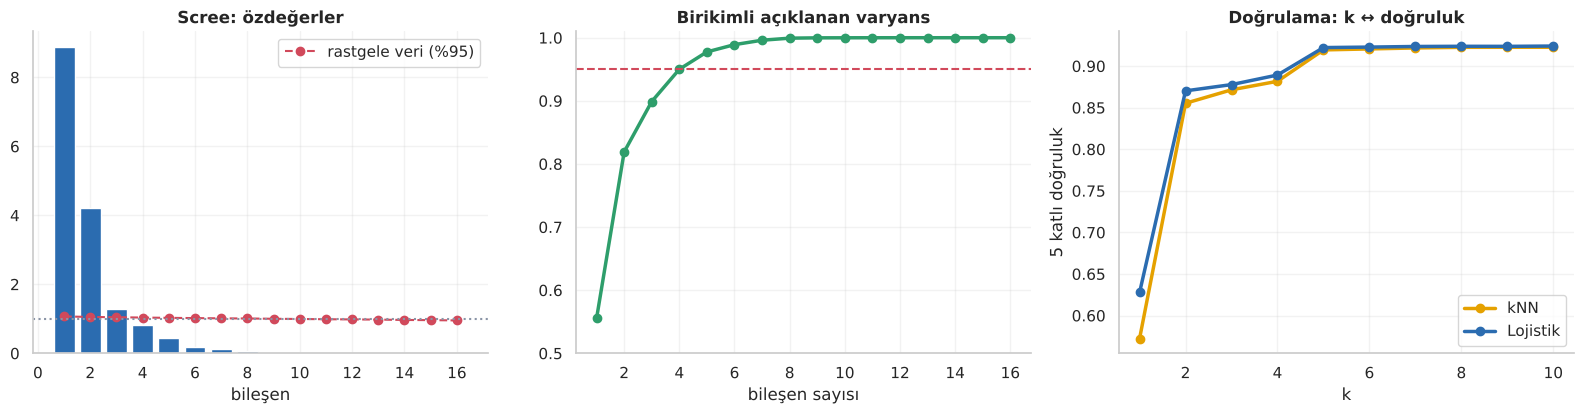


Birikimli varyans: PC1 %55.5 · ilk 2 %81.9 · ilk 4 %95.0 · ilk 6 %98.9
📄 Rapor → outputs/reports/kavram_kac_bilesen_kurallari.csv
📄 Rapor → outputs/reports/kavram_k_dogrulama.csv


In [12]:
Zt = StandardScaler().fit_transform(d[OZELLIKLER])
pca_t = PCA().fit(Zt)
lam = pca_t.explained_variance_; oran = pca_t.explained_variance_ratio_; kum = np.cumsum(oran)
p = len(lam)

kaiser = int((lam > 1).sum())
yuzde95 = int(np.argmax(kum >= 0.95) + 1)
# Dirsek: (1, λ1) ile (p, λp) arasındaki doğrudan en uzak nokta
xs = np.arange(1, p + 1); a_ = np.array([1, lam[0]]); b_ = np.array([p, lam[-1]])
dx, dy = b_ - a_
dist = np.abs(dx * (lam - a_[1]) - dy * (xs - a_[0])) / np.hypot(dx, dy)     # noktanın doğruya uzaklığı
dirsek = int(xs[dist.argmax()])
# Paralel analiz: her sütunu bağımsız karıştır, özdeğerlerin %95'ini eşik al
rng = np.random.default_rng(RANDOM_STATE); rast = []
for _ in range(40):
    Zr = np.column_stack([rng.permutation(Zt[:, j]) for j in range(p)])
    rast.append(PCA().fit(Zr).explained_variance_)
esik = np.percentile(rast, 95, axis=0)
paralel = int(np.argmax(lam <= esik)) if (lam <= esik).any() else p
mle = PCA(n_components="mle").fit(Zt).n_components_           # Minka (2000) olasılıksal kural

# Doğrulama: bileşen sayısı k için kNN ve lojistik regresyon doğruluğu
dog = []
for k in range(1, 11):
    dog.append({"k": k,
                "kNN": cross_val_score(make_pipeline(StandardScaler(), PCA(k), KNeighborsClassifier()), d[OZELLIKLER], d[HEDEF], cv=cv5).mean(),
                "Lojistik": cross_val_score(make_pipeline(StandardScaler(), PCA(k), LogisticRegression(max_iter=2000)), d[OZELLIKLER], d[HEDEF], cv=cv5).mean()})
dog = pd.DataFrame(dog).set_index("k")

kurallar = pd.DataFrame({"Kural": ["Kaiser (λ>1)", "%95 varyans", "Dirsek", "Paralel analiz", "Minka MLE"],
                         "Önerdiği bileşen sayısı": [kaiser, yuzde95, dirsek, paralel, mle]}).set_index("Kural")
display(kurallar)
display(dog.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].bar(xs, lam, color=RENK["mavi"]); ax[0].plot(xs, esik, "o--", color=RENK["pembe"], label="rastgele veri (%95)")
ax[0].axhline(1, color=RENK["gri"], ls=":"); ax[0].set_title("Scree: özdeğerler"); ax[0].set_xlabel("bileşen"); ax[0].legend()
ax[1].plot(xs, kum, "o-", color=RENK["yesil"], lw=2.5); ax[1].axhline(.95, color=RENK["pembe"], ls="--")
ax[1].set_title("Birikimli açıklanan varyans"); ax[1].set_xlabel("bileşen sayısı"); ax[1].set_ylim(.5, 1.01)
dog.plot(ax=ax[2], marker="o", lw=2.5, color=[RENK["altin"], RENK["mavi"]]); ax[2].set_title("Doğrulama: k ↔ doğruluk"); ax[2].set_ylabel("5 katlı doğruluk")
fig.tight_layout(); kaydet(fig, "kavram_06_kac_bilesen"); plt.show()
print(f"\nBirikimli varyans: PC1 %{kum[0]*100:.1f} · ilk 2 %{kum[1]*100:.1f} · ilk 4 %{kum[3]*100:.1f} · ilk 6 %{kum[5]*100:.1f}")
rapor_kaydet(kurallar, "kavram_kac_bilesen_kurallari"); rapor_kaydet(dog, "kavram_k_dogrulama")

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Kuralların cevapları **birbirinden farklı** çıkabilir; bu normaldir. Minka'nın olasılıksal kuralı (MLE) burada 15 bileşen önerdi: 13 bin satırda en küçük bileşenler bile istatistiksel olarak "gürültüden farklı" göründüğü için neredeyse hepsini tutar; **veri çoksa bu kural cömert davranır**. Doğrulama eğrisi ise başarının **5–6 bileşende platoya** ulaştığını gösteriyor. Pratikte iyi bir sıra: önce kurallarla **aday aralığı** bul, sonra **doğrulamayla** (modelin kendi başarısıyla) karar ver. Projede `k`'yı modelle birlikte **bir hiperparametre** gibi ayarlayacağız.

</td></tr></table>

### 🎞️ 6.2 · Varyans Nasıl Birikiyor? (Animasyon)

Bileşenleri tek tek ekleyip birikimli varyansı izleyelim; %95 çizgisini hangi bileşenin geçtiğini görün.

🎞️ Animasyon → outputs/figures/kavram_07_varyans_birikimi.gif


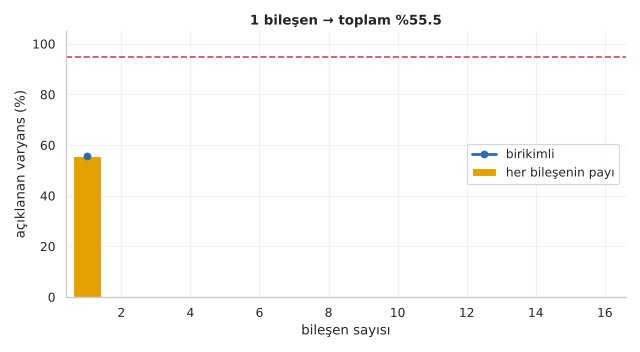

In [13]:
def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1); k = i + 1
    ax.bar(xs[:k], oran[:k] * 100, color=RENK["altin"], label="her bileşenin payı")
    ax.plot(xs[:k], kum[:k] * 100, "o-", color=RENK["mavi"], lw=2.5, label="birikimli")
    ax.axhline(95, color=RENK["pembe"], ls="--"); ax.set_xlim(.4, p + .6); ax.set_ylim(0, 105)
    ax.set_xlabel("bileşen sayısı"); ax.set_ylabel("açıklanan varyans (%)")
    ax.set_title(f"{k} bileşen → toplam %{kum[i]*100:.1f}"); ax.legend(loc="center right")
    fig.tight_layout()
gif_kaydet(kare, p, "kavram_07_varyans_birikimi", figsize=(8, 4.4), fps=3)

<a id="p7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7">
</p>

### 🗺️ 7.1 · 16 Ölçüden 2 Eksenli Harita

PCA'nın en sevilen işi: **görselleştirme**. 16 boyutlu fasulyeleri 2 boyuta (PC1, PC2) indirip türlere göre boyayalım. Eksenlerin ne anlama geldiğini de **yük (loading)** tablosundan okuyacağız: bir bileşenin hangi ölçüden ne kadar "aldığı".

Açıklanan varyans: [55.5 26.4  8.   5.1] % → ilk 2 bileşen toplamı % 81.9


💾 Kaydedildi → outputs/figures/kavram_08_fasulye_haritasi.png


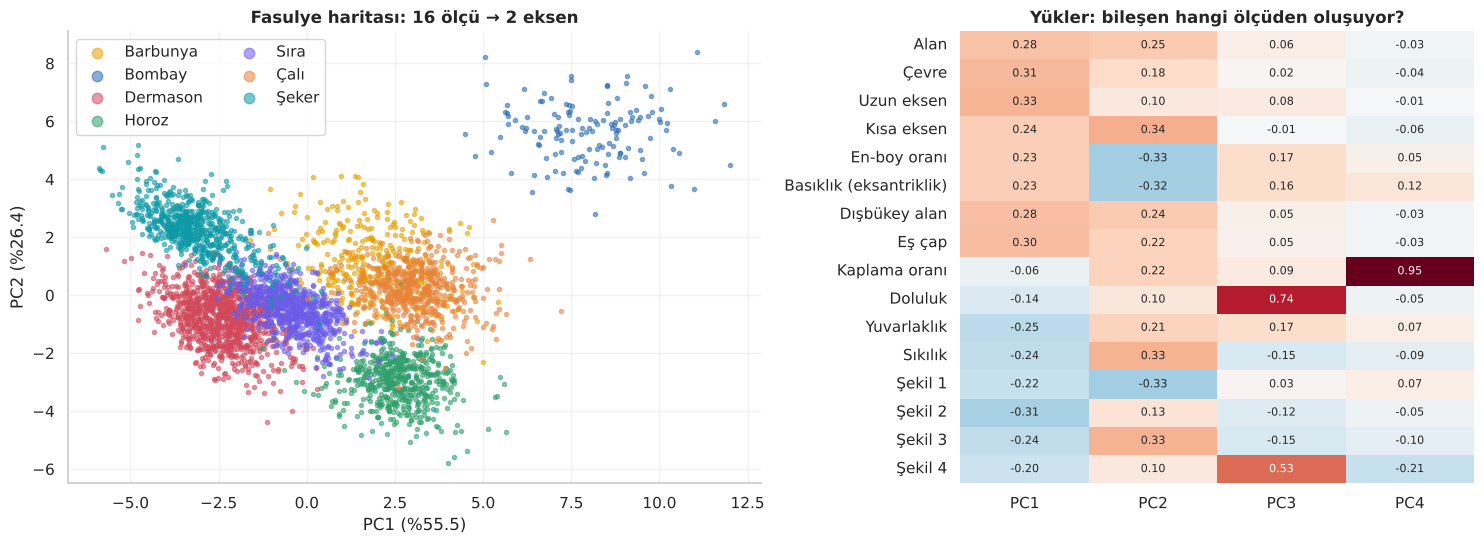

📄 Rapor → outputs/reports/kavram_yukler.csv


In [14]:
pca2 = PCA(n_components=4).fit(Zt)
S = pca2.transform(Zt)
yuk4 = pd.DataFrame(pca2.components_.T, index=[TR_AD[o] for o in OZELLIKLER], columns=[f"PC{i+1}" for i in range(4)])
oran4 = pca2.explained_variance_ratio_
print("Açıklanan varyans:", (oran4 * 100).round(1), "% → ilk 2 bileşen toplamı %", (oran4[:2].sum() * 100).round(1))

idx = np.random.default_rng(RANDOM_STATE).choice(len(S), 4000, replace=False)
tur_tr = d[HEDEF].map(SINIF_TR).to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.35, 1]})
for t in sorted(set(tur_tr)):
    m = tur_tr[idx] == t
    ax[0].scatter(S[idx][m, 0], S[idx][m, 1], s=9, alpha=.55, color=SINIF_RENK[t], label=t)
ax[0].set_xlabel(f"PC1 (%{oran4[0]*100:.1f})"); ax[0].set_ylabel(f"PC2 (%{oran4[1]*100:.1f})")
ax[0].set_title("Fasulye haritası: 16 ölçü → 2 eksen"); ax[0].legend(markerscale=2.5, ncol=2)
sns.heatmap(yuk4, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1], cbar=False, annot_kws={"size": 8})
ax[1].set_title("Yükler: bileşen hangi ölçüden oluşuyor?"); ax[1].grid(False)
fig.tight_layout(); kaydet(fig, "kavram_08_fasulye_haritasi"); plt.show()
rapor_kaydet(yuk4, "kavram_yukler")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Yük tablosunu okuyun: **PC1** büyük pozitif yükleri **boyut ölçülerinden** alıyor (alan, çevre, uzun eksen, eş çap, dışbükey alan) → "**fasulye ne kadar büyük?**" ekseni; şekil faktörleri ise ters yönde. **PC2**'nin pozitif ucunda **kısa eksen, sıkılık, şekil 3**, negatif ucunda **en-boy oranı, eksantriklik** var → "**fasulye yuvarlak mı, uzun mu?**" ekseni. Haritada **Bombay** (en iri ve en yuvarlağımsı) sağ üstte tek başına, **Şeker** sol üstte, **Horoz** altta ayrışıyor; **Dermason–Sıra** üst üste biniyor ve **Barbunya–Çalı** birbirine yakın: ayırması zor olan çiftler bunlar.

</td></tr></table>

### 🎞️ 7.2 · Fasulyeler Yerini Değiştiriyor (Animasyon)

Aşağıda aynı 1200 fasulye, **ham iki ölçüden** (alan ve çevre, standartlaştırılmış) **PCA haritasına** yumuşakça geçiyor.

🎞️ Animasyon → outputs/figures/kavram_09_harita_gecisi.gif


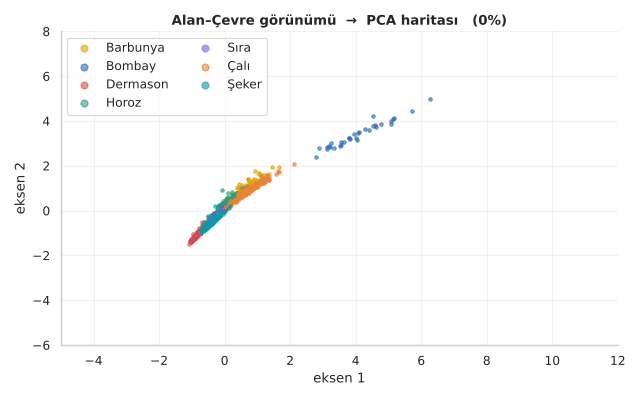

In [15]:
ii = idx[:1200]
ilk = np.c_[Zt[ii, 0], Zt[ii, 1]]          # alan ve çevre (standart)
son = S[ii, :2]
tt = tur_tr[ii]
adim = np.linspace(0, 1, 16); adim = np.r_[adim, np.ones(4)]
def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1); t = adim[i]; t = t * t * (3 - 2 * t)   # yumuşatma
    P = (1 - t) * ilk + t * son
    for ad in sorted(set(tt)):
        m = tt == ad; ax.scatter(P[m, 0], P[m, 1], s=10, alpha=.6, color=SINIF_RENK[ad], label=ad if i == 0 else None)
    ax.set_xlim(-5, 12); ax.set_ylim(-6, 8); ax.set_title("Alan–Çevre görünümü  →  PCA haritası" + f"   ({int(t*100)}%)")
    ax.set_xlabel("eksen 1"); ax.set_ylabel("eksen 2")
    if i == 0: ax.legend(markerscale=2, ncol=2, loc="upper left")
    fig.tight_layout()
gif_kaydet(kare, len(adim), "kavram_09_harita_gecisi", figsize=(8, 5), fps=6)

<a id="p8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8">
</p>

### 🔄 8.1 · Sıkıştırıp Geri Açmak

PCA bir **sıkıştırmadır**: 16 sayıyı k sayıya indirir. Peki geri açınca ne kadar benzer bir fasulye çıkar? Her k için **yeniden kurma hatasını** ölçelim:

$$\text{hata}(k) = \sqrt{1 - \text{birikimli varyans}(k)}$$

(Standartlaştırılmış uzayda, ortalama kare hatanın karekökü.) Formülün gerçekten tuttuğunu da doğrulayalım.

,Geri kurma hatası,√(1−birikimli varyans),Sıkıştırma
k,,,
1,0.6667,0.6667,16.0x
2,0.4254,0.4254,8.0x
3,0.3179,0.3179,5.3x
4,0.2236,0.2236,4.0x
5,0.1499,0.1499,3.2x
6,0.1046,0.1046,2.7x
7,0.0629,0.0629,2.3x
8,0.0265,0.0265,2.0x


Ölçüm ↔ formül en büyük fark: 6.505364823217175e-14


💾 Kaydedildi → outputs/figures/kavram_10_geri_kurma.png


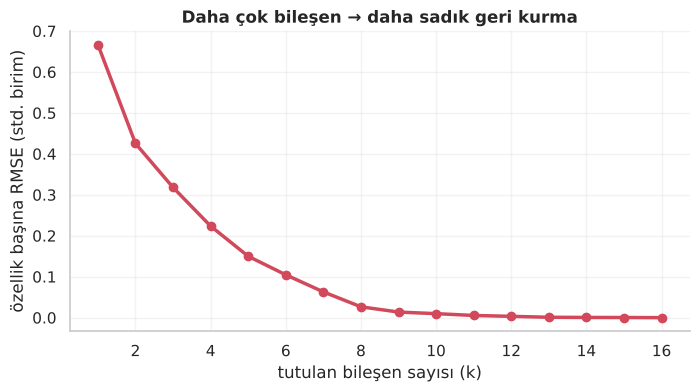

📄 Rapor → outputs/reports/kavram_geri_kurma.csv


In [16]:
hatalar = []
for k in range(1, 17):
    pk = PCA(n_components=k).fit(Zt)
    geri = pk.inverse_transform(pk.transform(Zt))
    olcum = np.sqrt(((Zt - geri) ** 2).sum(axis=1).mean() / p)      # özellik başına RMSE
    kuram = np.sqrt(1 - kum[k - 1]) if k < 16 else 0.0
    hatalar.append({"k": k, "Geri kurma hatası": olcum, "√(1−birikimli varyans)": kuram, "Sıkıştırma": f"{p/k:.1f}x"})
ht = pd.DataFrame(hatalar).set_index("k")
display(ht.head(8).round(4))
print("Ölçüm ↔ formül en büyük fark:", float(np.abs(ht["Geri kurma hatası"] - ht["√(1−birikimli varyans)"]).max()))
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.plot(ht.index, ht["Geri kurma hatası"], "o-", lw=2.5, color=RENK["pembe"]); ax.set_xlabel("tutulan bileşen sayısı (k)"); ax.set_ylabel("özellik başına RMSE (std. birim)")
ax.set_title("Daha çok bileşen → daha sadık geri kurma"); kaydet(fig, "kavram_10_geri_kurma"); plt.show()
rapor_kaydet(ht, "kavram_geri_kurma")

### 🎞️ 8.2 · Tek Bir Fasulyenin Geri Kurulumu (Animasyon)

Rastgele bir fasulyeyi alalım. Mavi çubuklar **gerçek** değerler (standart birimde), altın çubuklar **k bileşenle geri kurulan** değerler. k arttıkça çubuklar birbirine yaklaşır.

🎞️ Animasyon → outputs/figures/kavram_11_tek_fasulye_geri_kurma.gif


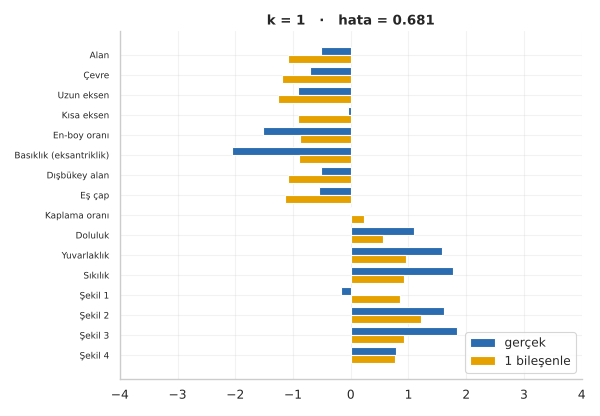

Fasulyenin türü: Şeker


In [17]:
i0 = 777
ad16 = [TR_AD[o] for o in OZELLIKLER]
def kare(i, fig):
    k = i + 1; pk = PCA(n_components=k).fit(Zt)
    g = pk.inverse_transform(pk.transform(Zt[[i0]]))[0]
    ax = fig.add_subplot(1, 1, 1); yy = np.arange(p)
    ax.barh(yy - .2, Zt[i0], height=.38, color=RENK["mavi"], label="gerçek")
    ax.barh(yy + .2, g, height=.38, color=RENK["altin"], label=f"{k} bileşenle")
    ax.set_yticks(yy); ax.set_yticklabels(ad16, fontsize=8); ax.invert_yaxis(); ax.set_xlim(-4, 4)
    ax.set_title(f"k = {k}   ·   hata = {np.sqrt(((Zt[i0]-g)**2).mean()):.3f}"); ax.legend(loc="lower right")
    fig.tight_layout()
gif_kaydet(kare, 16, "kavram_11_tek_fasulye_geri_kurma", figsize=(7.5, 5.2), fps=2)
print("Fasulyenin türü:", SINIF_TR[d.loc[i0, HEDEF]])

<a id="p9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9">
</p>

### ⚠️ 9.1 · Tuzak 1: Sızıntı

PCA bir **öğrenmedir** (eksenleri veriden öğrenir). Eksenleri **test verisini de görerek** öğrenirsek test, eğitime sızmış olur.

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="PCA sızıntısı">
</p>

Aynı veriyi iki şekilde değerlendirelim: (a) **önce tüm veriye PCA, sonra çapraz doğrulama** (yanlış), (b) **PCA her katta yalnızca eğitim kısmında** (doğru).

In [18]:
Xk = d[OZELLIKLER]; yk = d[HEDEF]
cvr = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

# (a) YANLIŞ: ölçekleme + PCA tüm veride, sonra CV
Zall = PCA(4).fit_transform(StandardScaler().fit_transform(Xk))
yanlis = cross_val_score(KNeighborsClassifier(), Zall, yk, cv=cvr)
# (b) DOĞRU: her katta boru hattı baştan kurulur
dogru = cross_val_score(make_pipeline(StandardScaler(), PCA(4), KNeighborsClassifier()), Xk, yk, cv=cvr)
print(f"Sızıntılı  : {yanlis.mean():.4f} ± {yanlis.std():.4f}")
print(f"Sızıntısız : {dogru.mean():.4f} ± {dogru.std():.4f}")
print(f"Fark       : {yanlis.mean() - dogru.mean():+.4f}")

Sızıntılı  : 0.8818 ± 0.0052
Sızıntısız : 0.8816 ± 0.0052
Fark       : +0.0001


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Bu veride fark **çok küçük** çıkar; çünkü PCA **etiketi kullanmaz** ve 13 bin satırlık veride eksenler kararlıdır. Küçük, çok sütunlu veride (örneğin 100 satır, 1000 sütun) fark büyüyebilir. **Kural değişmez:** PCA ve ölçekleyici *her zaman* boru hattının içinde, yalnızca eğitim katında öğrenilir.

</td></tr></table>

### 🫥 9.2 · Tuzak 2: Önemli Ayrım Düşük Varyanslı Olabilir

PCA **etiketi görmez**; yalnızca "en çok yayılan yön"ü arar. Ama sınıfları ayıran yön **az yayılan** bir yön olabilir! Bunu **yapay (sentetik)** bir veriyle gösterelim *(bu veri gerçek değildir, kavramı göstermek için üretildi)*: birinci ölçü büyük gürültü (sınıfla ilgisiz), ikinci ölçü küçük ama sınıfı **tam ayıran** sinyal.

PCA(1) + lojistik : 0.553   ← PCA yalnızca yayılıma baktı, sinyali attı
Ham 2 ölçü        : 1.000
LDA (etiketi kullanır): 1.000


💾 Kaydedildi → outputs/figures/kavram_12_gizli_ayrim.png


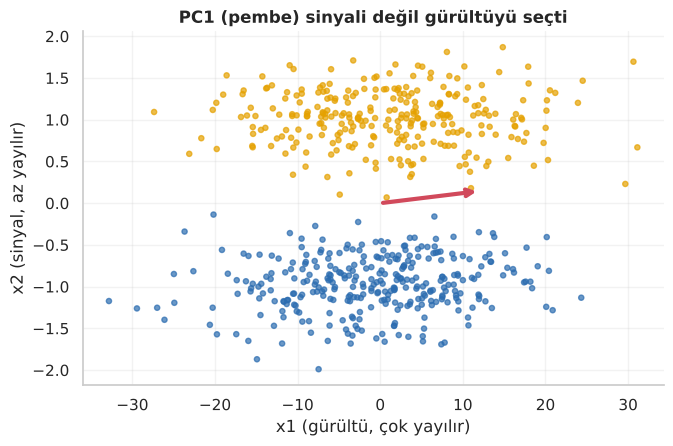

In [19]:
rng = np.random.default_rng(5)
n = 600; sinif = rng.integers(0, 2, n)
x1 = rng.normal(0, 10, n)                      # çok yayılan, sınıfla ilgisiz
x2 = (sinif * 2 - 1) * 1.0 + rng.normal(0, .35, n)   # az yayılan ama sınıfı ayıran
Xs = np.c_[x1, x2]
cv5b = StratifiedKFold(5, shuffle=True, random_state=0)
a1 = cross_val_score(make_pipeline(PCA(1), LogisticRegression()), Xs, sinif, cv=cv5b).mean()
a2 = cross_val_score(LogisticRegression(), Xs, sinif, cv=cv5b).mean()
a3 = cross_val_score(LinearDiscriminantAnalysis(), Xs, sinif, cv=cv5b).mean()
print(f"PCA(1) + lojistik : {a1:.3f}   ← PCA yalnızca yayılıma baktı, sinyali attı")
print(f"Ham 2 ölçü        : {a2:.3f}")
print(f"LDA (etiketi kullanır): {a3:.3f}")

pc = PCA(2).fit(Xs)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.scatter(Xs[:, 0], Xs[:, 1], c=np.where(sinif == 1, RENK["altin"], RENK["mavi"]), s=14, alpha=.7)
for j, r in enumerate([RENK["pembe"], RENK["yesil"]]):
    ax.annotate("", xy=pc.components_[j] * 12, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=r, lw=3))
ax.set_title("PC1 (pembe) sinyali değil gürültüyü seçti"); ax.set_xlabel("x1 (gürültü, çok yayılır)"); ax.set_ylabel("x2 (sinyal, az yayılır)")
kaydet(fig, "kavram_12_gizli_ayrim"); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

PCA **denetimsizdir**: etiketi bilmez. Bu yüzden "PCA her zaman başarıyı artırır" diye bir şey yoktur. Bileşen sayısı **mutlaka** modelin başarısıyla (çapraz doğrulama) kontrol edilmelidir; gerekirse etiketi kullanan yöntemler (LDA gibi) düşünülmelidir.

</td></tr></table>

### 🪨 9.3 · Tuzak 3: Aykırı Değer Ekseni Çekebilir

PCA varyansa bakar; **tek bir uç nokta** varyansı şişirip ekseni kendine doğru **döndürebilir**. Gerçek veride (alan–eksantriklik) 5 yapay uç nokta ekleyip PC1'in açısındaki değişimi ölçelim.

PC1 açısı  temiz: 135.0°  →  5 uç nokta ile: 45.0°


💾 Kaydedildi → outputs/figures/kavram_13_aykiri_etkisi.png


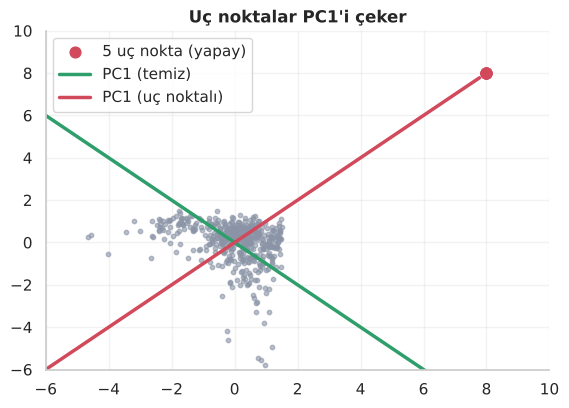

In [20]:
iki = StandardScaler().fit_transform(d[["Eccentricity", "Solidity"]].sample(500, random_state=1))
def aci(M): v = PCA(1).fit(M).components_[0]; return np.degrees(np.arctan2(v[1], v[0])) % 180
temiz = aci(iki)
uc = np.r_[iki, np.tile([[8.0, 8.0]], (5, 1))]          # 5 yapay uç nokta
print(f"PC1 açısı  temiz: {temiz:.1f}°  →  5 uç nokta ile: {aci(uc):.1f}°")
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.scatter(iki[:, 0], iki[:, 1], s=10, color=RENK["gri"], alpha=.6); ax.scatter(uc[-5:, 0], uc[-5:, 1], s=60, color=RENK["pembe"], label="5 uç nokta (yapay)")
for M_, r, ad in [(iki, RENK["yesil"], "temiz"), (uc, RENK["pembe"], "uç noktalı")]:
    v = PCA(1).fit(M_).components_[0]; ax.plot([-11 * v[0], 11 * v[0]], [-11 * v[1], 11 * v[1]], color=r, lw=2.5, label=f"PC1 ({ad})")
ax.set_xlim(-6, 10); ax.set_ylim(-6, 10); ax.legend(); ax.set_title("Uç noktalar PC1'i çeker")
kaydet(fig, "kavram_13_aykiri_etkisi"); plt.show()

### 🧩 9.4 · Tuzak 4: Yorumlamak Zorlaşır

Yeni eksenler (PC1, PC2…) **orijinal ölçülerin karışımıdır**; "PC2 = 0,3·sıkılık − 0,25·yuvarlaklık + …" gibi bir şeyi bir fabrika sorumlusuna anlatmak zordur. Yönetici raporunda gerekirse **yük tablosuyla** "PC1 ≈ boyut, PC2 ≈ şekil" gibi bir etiket yazılır; ama bu bir **yorumdur, kanıt değil**.

<a id="p10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10">
</p>

### 🎞️ 10.1 · PCA'nın Filmi

Tüm adımları tek animasyonda birleştirelim (uzun eksen × kısa eksen, 500 fasulye):

1. **Ham veri** (gerçek birimler)
2. **Standartlaştırma** (merkez 0'a, yayılım 1'e)
3. **Döndürme** (eksenler PC1–PC2'ye hizalanır)
4. **Sıkıştırma** (PC2 sıfıra ezilir → sadece PC1 kalır)
5. **Geri kurma** (PC1'den geri dönüş; kaybolan bilgi = uzak kalan fark)

🎞️ Animasyon → outputs/figures/kavram_14_pca_filmi.gif


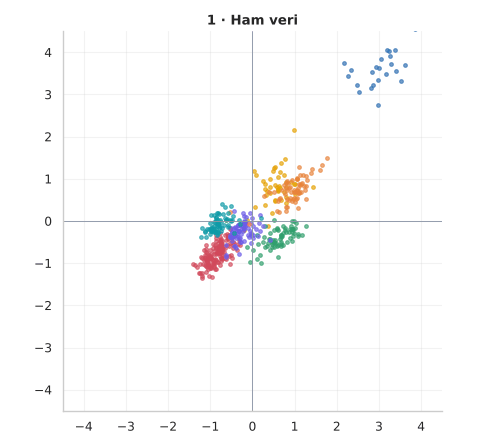

Sıkıştırmada kaybolan bilgi payı: %7.8


In [21]:
ik5 = X[["Uzun eksen", "Kısa eksen"]].sample(500, random_state=RANDOM_STATE)
tur5 = y.loc[ik5.index].to_numpy()
ham5 = ik5.to_numpy(); sc5 = StandardScaler().fit(ham5); Z5 = sc5.transform(ham5)
p5 = PCA(2).fit(Z5); R5 = Z5 @ p5.components_.T            # döndürülmüş koordinatlar (PC1, PC2)
ezik = R5.copy(); ezik[:, 1] = 0                           # PC2 → 0
geri5 = ezik @ p5.components_                              # standart uzaya geri
# Ham veriyi de [-4,4] aralığına sığdırmak için görsel ölçekle (yalnızca çizim için)
ham_gor = (ham5 - ham5.mean(0)) / (ham5.std(0) * 1.0) * 1.0
kareler = []
def ara(a, b, n=7):
    return [(1 - (t * t * (3 - 2 * t))) * a + (t * t * (3 - 2 * t)) * b for t in np.linspace(0, 1, n)]
dizi = [(ham_gor, "1 · Ham veri")] * 3
for ad_, (a, b) in zip(["2 · Standartlaştırma", "3 · Döndürme: PC eksenleri", "4 · Sıkıştırma: PC2 atılır", "5 · Geri kurma"],
                       [(ham_gor, Z5), (Z5, R5), (R5, ezik), (ezik, geri5)]):
    dizi += [(m, ad_) for m in ara(a, b)] + [(b, ad_)] * 2
def kare(i, fig):
    M, ad = dizi[i]; ax = fig.add_subplot(1, 1, 1)
    for t in sorted(set(tur5)):
        m = tur5 == t; ax.scatter(M[m, 0], M[m, 1], s=11, alpha=.65, color=SINIF_RENK[t])
    ax.axhline(0, color=RENK["gri"], lw=.8); ax.axvline(0, color=RENK["gri"], lw=.8)
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect("equal"); ax.set_title(ad)
    fig.tight_layout()
gif_kaydet(kare, len(dizi), "kavram_14_pca_filmi", figsize=(6.2, 5.6), fps=7)
print(f"Sıkıştırmada kaybolan bilgi payı: %{(1 - p5.explained_variance_ratio_[0]) * 100:.1f}")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Son karede noktalar **tek bir doğru üzerinde** toplanır: iki ölçüyü **tek bir sayıya** (PC1) indirdik ve geri açınca yalnızca küçük bir bilgi kaybı oldu. Bu, PCA'nın tüm gücü: **birlikte değişen ölçüleri tek ölçüde toplamak**.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🔦</h3><b>Gölge fikri</b><br><sub><i>en geniş yayılım</i></sub><br><br>PCA, veriye <b>gölgesi en çok yayılan açıdan</b> bakar; bu yön PC1'dir<br><br></td><td width="33%" valign="top" align="center"><h3>🧮</h3><b>Beş adım</b><br><sub><i>std → kovaryans → özvektör → seç → izdüşüm</i></sub><br><br>Elle hesapla `scikit-learn` <b>birebir aynı</b> çıktı<br><br></td><td width="33%" valign="top" align="center"><h3>➗</h3><b>Önce ölçekle</b><br><sub><i>StandardScaler</i></sub><br><br>Ölçeksiz PCA'da büyük sayılı ölçüler <b>haksız üstünlük</b> kurar<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>📉</h3><b>Kaç bileşen?</b><br><sub><i>kural + doğrulama</i></sub><br><br>Kurallar aday verir; karar <b>modelin başarısıyla</b> verilir<br><br></td><td width="33%" valign="top" align="center"><h3>🔄</h3><b>Sıkıştırma kayıplıdır</b><br><sub><i>hata = √(1 − birikimli varyans)</i></sub><br><br>Daha çok bileşen, daha sadık geri kurma<br><br></td><td width="33%" valign="top" align="center"><h3>⚠️</h3><b>Tuzaklar</b><br><sub><i>sızıntı · gizli ayrım · aykırı</i></sub><br><br>PCA <b>etiketi görmez</b>; her zaman boru hattının içinde ve doğrulanarak kullan<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> PCA'nın amacı nedir ve neden "özellik çıkarımı" sayılır?</summary>

Birbirine bağlı (korelasyonlu) ölçüleri **birleştirerek** varyansı en çok koruyan daha az sayıda **yeni** ölçü üretmektir. Var olan ölçülerden seçmediği, yeni ölçüler **ürettiği** için özellik seçimi değil, özellik çıkarımıdır.
</details>

<details><summary><b>2.</b> Özvektör ve özdeğer PCA'da neyi anlatır?</summary>

**Özvektör:** verinin yayılma **yönü** (yeni eksen). **Özdeğer:** o yönde **ne kadar** yayılım (varyans) olduğu. En büyük özdeğerli özvektör PC1'dir.
</details>

<details><summary><b>3.</b> PCA'dan önce neden standartlaştırırız?</summary>

PCA varyansa bakar. Ölçekler farklıysa **sayısı büyük olan ölçü** (örneğin alan) varyansı domine eder ve PC1 sırf onu taşır. Standartlaştırma tüm ölçülere eşit söz hakkı verir.
</details>

<details><summary><b>4.</b> Neden PCA'yı tüm veriye uygulayıp sonra train/test'e bölmemeliyiz?</summary>

PCA eksenleri **veriden öğrenir**. Testi de görerek öğrenirse test bilgisi eğitime **sızar**; skor iyimser çıkar. Doğrusu: `Pipeline(StandardScaler, PCA, Model)` kurmak ve her katta yalnızca eğitim kısmında öğrenmektir.
</details>

<details><summary><b>5.</b> PCA her zaman model başarısını artırır mı?</summary>

Hayır. PCA etiketi görmez; sınıfları ayıran yön **az yayılan** bir yön olabilir ve atılabilir. Bu derste hem sentetik örnekte hem fasulye verisinde gördük: bileşen sayısı **doğrulamayla** seçilmeli.
</details>

### 🏠 Ödevler

1. 4. durakta `random_state=3` yerine **farklı bir 8 fasulye** seçip hesabı tekrarlayın: özvektörler ve PC1 oranı nasıl değişiyor?
2. 2.2'deki gürültü deneyini **`StratifiedKFold` yerine** `RepeatedStratifiedKFold` ile tekrarlayın; sonuçlar kararlı mı?
3. 6.1'deki beş kurala göre seçilen `k` değerleriyle **SVC** başarısını kıyaslayın.
4. 7.1'deki haritayı **PC1–PC3** ile çizin; üç boyutta Dermason ve Sıra ayrışıyor mu?
5. *(Zor)* 9.2'deki sentetik örnekte **sinyalin yayılımını** adım adım artırın (örn. 0,35 → 5) ve PCA(1)'in hangi noktada kurtulduğunu bulun.

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir. Bu notebook'ta örnek: *PCA'nın kökeni Pearson (1901) ve Hotelling (1933) çalışmalarına dayanır (Pearson, 1901; Hotelling, 1933; Jolliffe ve Cadima, 2016'dan aktarma).* Çok boyutlu verinin sorunları için Bellman (1961) (Hastie ve ark., 2009'dan aktarma) ve güncel bir derleme olarak Greenacre ve ark. (2022) esas alınmıştır. *Not: Jolliffe ve Cadima (2016) ile Greenacre ve ark. (2022) makalelerinin tam metnine bu çalışma ortamından ulaşılamadı; künyeleri yayıncı/özet sayfalarından doğrulandı. Dolaylı atıfların sayfa düzeyinde doğrulaması kullanıcıya bırakılmıştır.*

- Bellman, R. (1961). *Adaptive control processes: A guided tour*. Princeton University Press.
- Cattell, R. B. (1966). The scree test for the number of factors. *Multivariate Behavioral Research, 1*(2), 245–276. https://doi.org/10.1207/s15327906mbr0102_10
- Greenacre, M., Groenen, P. J. F., Hastie, T., D'Enza, A. I., Markos, A., & Tuzhilina, E. (2022). Principal component analysis. *Nature Reviews Methods Primers, 2*, Article 100. https://doi.org/10.1038/s43586-022-00184-w
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer.
- Hotelling, H. (1933). Analysis of a complex of statistical variables into principal components. *Journal of Educational Psychology, 24*(6), 417–441. https://doi.org/10.1037/h0071325
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), Article 20150202. https://doi.org/10.1098/rsta.2015.0202
- Kaiser, H. F. (1960). The application of electronic computers to factor analysis. *Educational and Psychological Measurement, 20*(1), 141–151. https://doi.org/10.1177/001316446002000116
- Koklu, M., & Özkan, İ. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, Article 105507. https://doi.org/10.1016/j.compag.2020.105507
- Minka, T. P. (2000). Automatic choice of dimensionality for PCA. *Advances in Neural Information Processing Systems, 13*, 598–604.
- Pearson, K. (1901). On lines and planes of closest fit to systems of points in space. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science, 2*(11), 559–572. https://doi.org/10.1080/14786440109462720
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Samancıoğlu, A. (t.y.). *Principal Component Analysis (PCA)* [Ders notu]. Yapay Zekâ ve Veri Bilimi Bootcamp.